In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
import xgboost as xgb

model = xgb.XGBClassifier()
model.load_model("D:\projects\creditcard_fraud\notebooks\models\xgboost_v1\model.json")

In [3]:
RAW_DATA_PATH = Path("data/creditcard_1.csv")
df = pd.read_csv(RAW_DATA_PATH)
df = df.sort_values("Time").reset_index(drop = True)

target_column = "Class"

split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df.drop(columns=[target_column])
y_train = train_df[target_column]

X_test = test_df.drop(columns=[target_column])
y_test = test_df[target_column]

In [4]:
print(X_test.shape)
print(y_test.shape)

(56962, 30)
(56962,)


In [5]:
print(X_test.columns.tolist())
print(model.feature_names_in_)

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
['Time' 'V1' 'V2' 'V3' 'V4' 'V5' 'V6' 'V7' 'V8' 'V9' 'V10' 'V11' 'V12'
 'V13' 'V14' 'V15' 'V16' 'V17' 'V18' 'V19' 'V20' 'V21' 'V22' 'V23' 'V24'
 'V25' 'V26' 'V27' 'V28' 'Amount']


In [6]:
import shap

explainer = shap.TreeExplainer(model)

C:\Users\Abhishek Goswami\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
shap_values = explainer.shap_values(X_test)

In [8]:
print(type(shap_values))
print(shap_values.shape)

<class 'numpy.ndarray'>
(56962, 30)


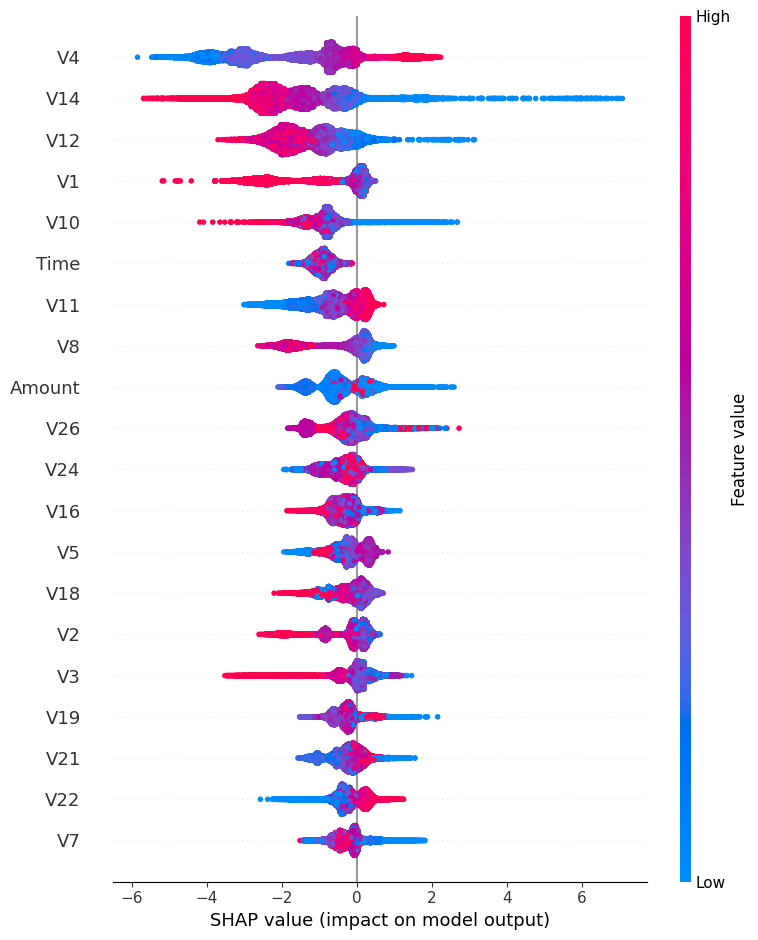

In [9]:
shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

In [10]:


output_dir = Path("reports/explainability")
output_dir.mkdir(parents=True, exist_ok=True)


import matplotlib.pyplot as plt

plt.savefig(
    output_dir / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

<Figure size 640x480 with 0 Axes>

### Mean absolute SHAP

In [11]:


feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_abs_shap": abs(shap_values).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    "mean_abs_shap",
    ascending=False
)

feature_importance.head(10)

,feature,mean_abs_shap
4,V4,1.818708
14,V14,1.614985
12,V12,1.245782
1,V1,0.969401
10,V10,0.945095
0,Time,0.927543
11,V11,0.683192
8,V8,0.631874
29,Amount,0.578361
26,V26,0.456877


In [12]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

In [13]:
results = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred,
    "fraud_probability": y_prob
})
results

,actual,predicted,fraud_probability
227845,0,0,1.158295e-05
227846,0,0,1.198055e-05
227847,0,0,1.205754e-08
227848,0,0,3.221699e-06
227849,0,0,4.404074e-04
...,...,...,...
284802,0,0,1.001791e-10
284803,0,0,5.324794e-06
284804,0,0,5.487861e-06
284805,0,0,5.505241e-07


In [14]:
# True Positive
tp_candidates = results[
    (results["actual"] == 1) &
    (results["predicted"] == 1)
]

# False Positive
fp_candidates = results[
    (results["actual"] == 0) &
    (results["predicted"] == 1)
]

# False Negative
fn_candidates = results[
    (results["actual"] == 1) &
    (results["predicted"] == 0)
]

print("TP count:", len(tp_candidates))
print("FP count:", len(fp_candidates))
print("FN count:", len(fn_candidates))

TP count: 56
FP count: 12
FN count: 19


In [15]:
print("TP candidates:")
display(tp_candidates.sort_values("fraud_probability", ascending=False).head())

print("\nFP candidates:")
display(fp_candidates.sort_values("fraud_probability", ascending=False).head())

print("\nFN candidates:")
display(fn_candidates.sort_values("fraud_probability", ascending=False).head())

TP candidates:


,actual,predicted,fraud_probability
276864,1,1,0.999998
263324,1,1,0.999996
243749,1,1,0.999993
279863,1,1,0.999992
261925,1,1,0.999990



FP candidates:


,actual,predicted,fraud_probability
274467,0,1,0.999507
228505,0,1,0.979516
266590,0,1,0.970438
274771,0,1,0.955296
267760,0,1,0.942966



FN candidates:


,actual,predicted,fraud_probability
274475,1,0,0.360186
240222,1,0,0.102733
251889,1,0,0.081375
239501,1,0,0.061681
229727,1,0,0.042990


In [16]:
tp_idx = tp_candidates["fraud_probability"].idxmax()
fp_idx = fp_candidates["fraud_probability"].idxmax()
fn_idx = fn_candidates["fraud_probability"].idxmax()

selected = results.loc[[tp_idx, fp_idx, fn_idx]]

display(selected)

,actual,predicted,fraud_probability
276864,1,1,0.999998
274467,0,1,0.999507
274475,1,0,0.360186


In [17]:
assert results.loc[tp_idx, "actual"] == 1
assert results.loc[tp_idx, "predicted"] == 1

assert results.loc[fp_idx, "actual"] == 0
assert results.loc[fp_idx, "predicted"] == 1

assert results.loc[fn_idx, "actual"] == 1
assert results.loc[fn_idx, "predicted"] == 0

In [18]:

print("Expected value:", explainer.expected_value)

Expected value: -0.11433641


In [19]:
X_tp = X_test.loc[[tp_idx]]
X_fp = X_test.loc[[fp_idx]]
X_fn = X_test.loc[[fn_idx]]
shap_tp = explainer(X_tp)
shap_fp = explainer(X_fp)
shap_fn = explainer(X_fn)
print("TP SHAP shape:", shap_tp.values.shape)
print("FP SHAP shape:", shap_fp.values.shape)
print("FN SHAP shape:", shap_fn.values.shape)

TP SHAP shape: (1, 30)
FP SHAP shape: (1, 30)
FN SHAP shape: (1, 30)


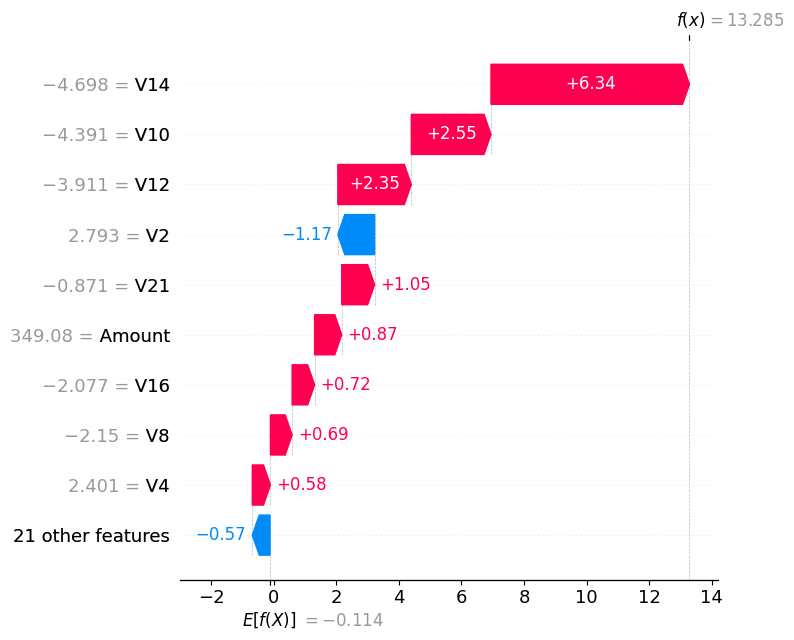

In [20]:
import matplotlib.pyplot as plt

shap.plots.waterfall(
    shap_tp[0],
    show=False
)

plt.tight_layout()
plt.savefig(
    "reports/explainability/shap_tp.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

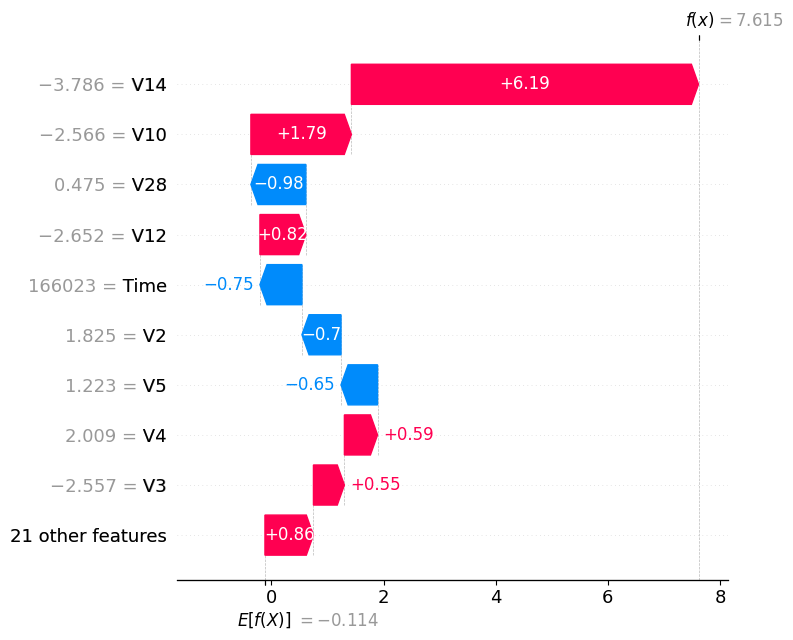

In [21]:
shap.plots.waterfall(
    shap_fp[0],
    show=False
)

plt.tight_layout()
plt.savefig(
    "reports/explainability/shap_fp.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

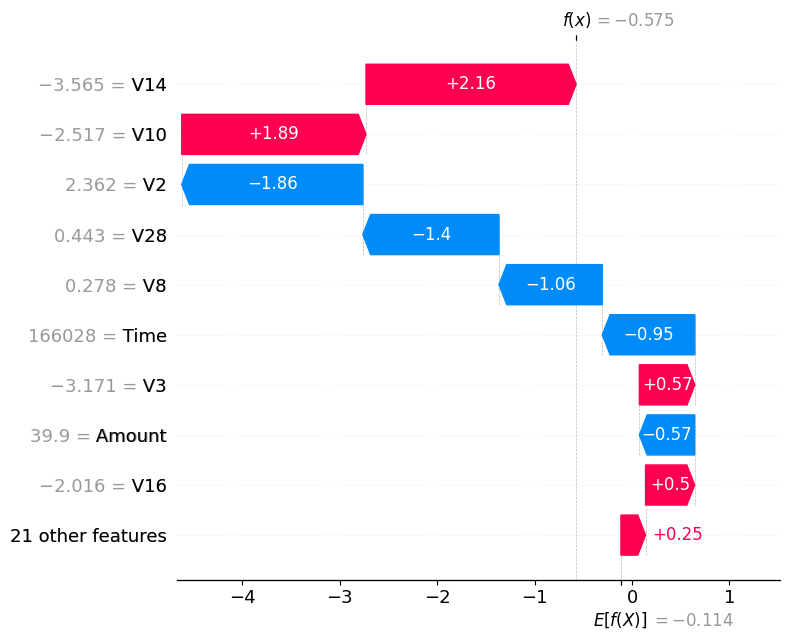

In [22]:
shap.plots.waterfall(
    shap_fn[0],
    show=False
)

plt.tight_layout()
plt.savefig(
    "reports/explainability/shap_fn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

In [23]:
def get_local_shap_table(shap_explanation):
    values = shap_explanation.values[0]
    
    return (
        pd.DataFrame({
            "feature": X_test.columns,
            "shap_value": values,
            "abs_shap": abs(values)
        })
        .sort_values("abs_shap", ascending=False)
    )
tp_table = get_local_shap_table(shap_tp)
fp_table = get_local_shap_table(shap_fp)
fn_table = get_local_shap_table(shap_fn)

print("TP:")
display(tp_table.head(10))

print("FP:")
display(fp_table.head(10))

print("FN:")
display(fn_table.head(10))

TP:


,feature,shap_value,abs_shap
14,V14,6.341073,6.341073
10,V10,2.545474,2.545474
12,V12,2.346457,2.346457
2,V2,-1.174053,1.174053
21,V21,1.050674,1.050674
29,Amount,0.865655,0.865655
16,V16,0.718197,0.718197
8,V8,0.692556,0.692556
4,V4,0.579870,0.579870
7,V7,0.554079,0.554079


FP:


,feature,shap_value,abs_shap
14,V14,6.188727,6.188727
10,V10,1.791351,1.791351
28,V28,-0.979347,0.979347
12,V12,0.818303,0.818303
0,Time,-0.748909,0.748909
2,V2,-0.696630,0.696630
5,V5,-0.651438,0.651438
4,V4,0.591288,0.591288
3,V3,0.551695,0.551695
17,V17,0.477016,0.477016


FN:


,feature,shap_value,abs_shap
14,V14,2.157101,2.157101
10,V10,1.891955,1.891955
2,V2,-1.859705,1.859705
28,V28,-1.397488,1.397488
8,V8,-1.061127,1.061127
0,Time,-0.949759,0.949759
3,V3,0.569120,0.569120
29,Amount,-0.567232,0.567232
16,V16,0.504067,0.504067
9,V9,-0.442244,0.442244


In [24]:
from layer1_fraud.explainability.shap_explaner import SHAPExplainer
shap_service = SHAPExplainer(model = model, X_test=X_test)
tp_explanation = shap_service.get_shap_explanation(
    transaction_id=276864,
    top_k=5
)

tp_explanation

ModuleNotFoundError: No module named 'layer1_fraud'